In [1]:
import os

from pathlib import Path

master_ = ''
path_splitted = os.getcwd().split(os.sep)

for entry in path_splitted:
    if entry == 'jupyter_spectrograms':
        break
    master_ = master_ + entry + os.sep
os.chdir(master_)

# Spektrogramski prikaz šuma

In [7]:
# importi i pomocne funkcije koje cemo koristiti

import numpy as np
import matplotlib.pyplot as plt

from scipy.io import wavfile
from scipy.signal import stft

def load_wav(path: str):
    fs, x = wavfile.read(path)
    x = x.astype(np.float32)
    x /= np.max(np.abs(x)+1e-9)
    return fs, x

def spectrogram_db(x, fs, nperseg=1024, noverlap=512):
    f, t, Z = stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap)
    S = 20 * np.log10(np.abs(Z) + 1e-8)
    return f, t, S

window_functions = {
    '_none_' : 'None',
    '_hamming_' : 'Hamming',
    '_hann_' : 'Hann',
    '_parzen_' : 'Parzen',
    '_welch_' : 'Welch',
    '_flat_' : 'Flat Top',
}

In [4]:
# Originalan audio
fs, original = load_wav("data/rusija_mono.wav")

duration = 30.0
num_samples = int(duration * fs)

# Originalni spektrogram
f,t,S_orig = spectrogram_db(original[:num_samples],fs)

# Bijeli (normalan šum)

Pogledajmo kako se na spektrogramu manifestuje šum, imaćemo uporedo prikaz dva spektrograma i pogledaćemo razliku koja nastaje.
Posmatramo sve u okviru prvih 30 sekundi

In [5]:
norm_fs, norm_original = load_wav("data/sample/normal/rusija.wav")

duration = 30.0
num_samples = int(duration * norm_fs)

norm_f, norm_t, norm_S_orig = spectrogram_db(norm_original[:num_samples],norm_fs)

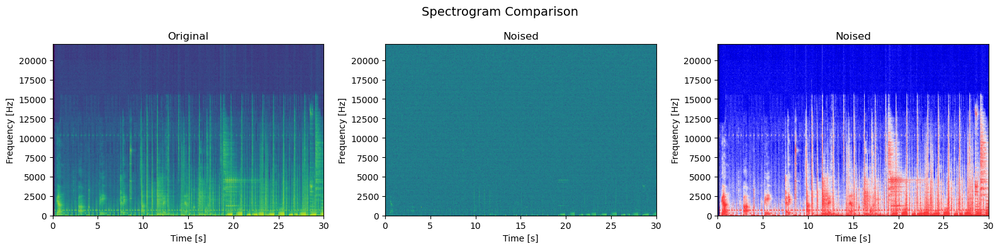

In [11]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.pcolormesh(t, f, S_orig, shading="gouraud")
plt.title("Original")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 2)
plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud", vmin=-80, vmax=0)
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 3)
plt.pcolormesh(t, f, S_orig - norm_S_orig, shading="gouraud",cmap="seismic")
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.suptitle(f"Spectrogram Comparison", fontsize=14)
plt.tight_layout()
plt.show()

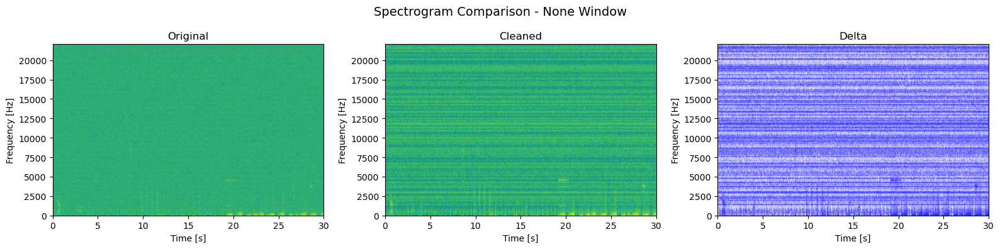

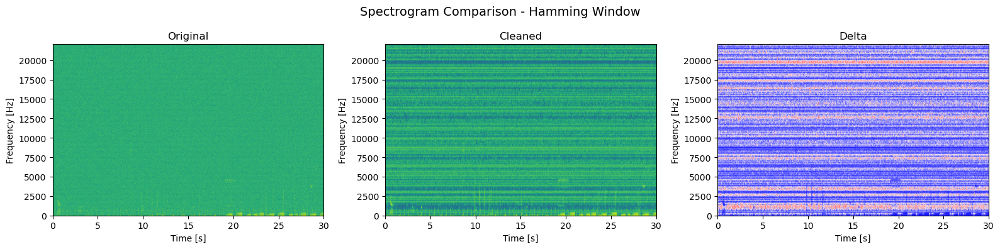

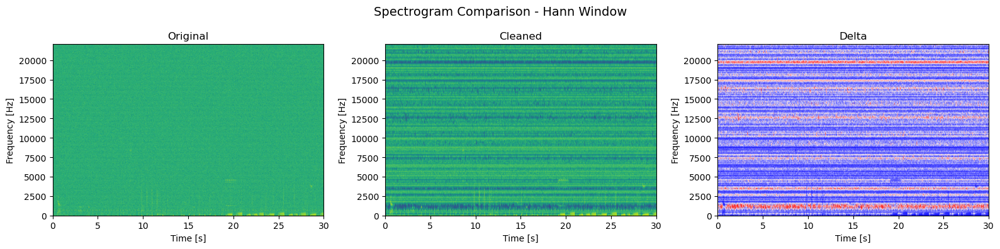

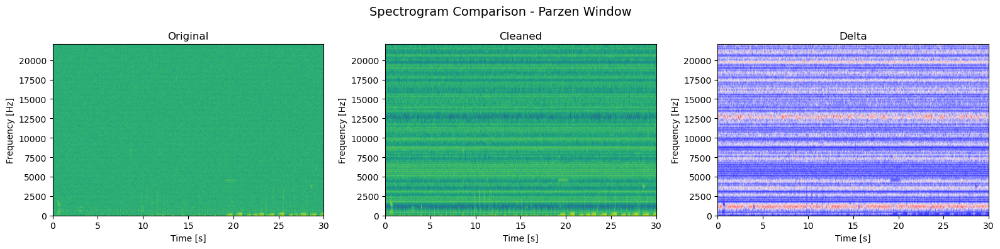

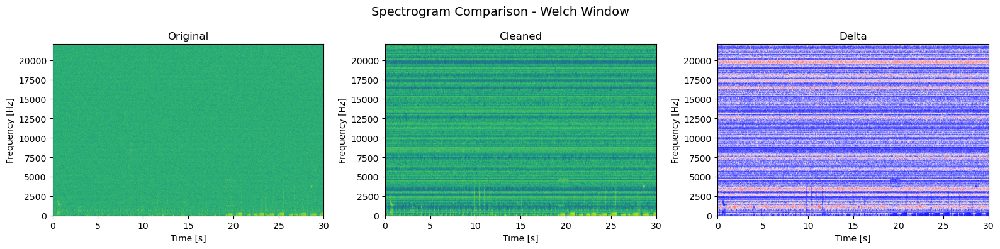

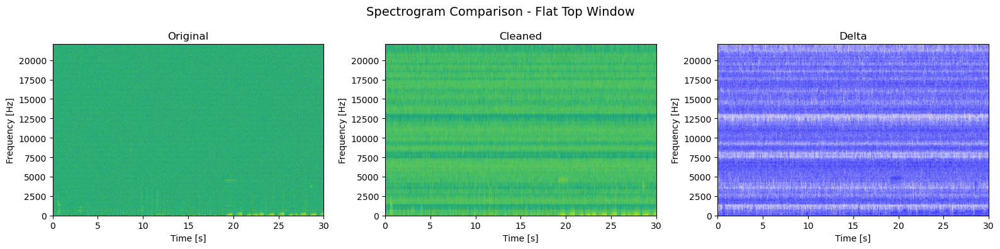

In [12]:
# samo skiciramo za faktor 1.5f (1.500000)
factor_ = '2.000000'
for key, item in window_functions.items():
    file_path = f'data/cleaned/normal/rusija{key}{factor_}.wav'
    tmp_fs, tmp_original = load_wav(file_path)

    duration = 30.0
    num_samples = int(duration * norm_fs)
    
    tmp_f, tmp_t, tmp_S_orig = spectrogram_db(tmp_original[:num_samples],tmp_fs)

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 3, 1)
    plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud")
    plt.title("Original")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 2)
    plt.pcolormesh(tmp_t, tmp_f, tmp_S_orig, shading="gouraud")
    plt.title("Cleaned")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 3)
    plt.pcolormesh(t, f, norm_S_orig - tmp_S_orig, shading="gouraud",cmap="seismic")
    plt.title("Delta")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.suptitle(f"Spectrogram Comparison - {item} Window", fontsize=14)
    plt.tight_layout()
    plt.show()


# Rozi šum

In [13]:
norm_fs, norm_original = load_wav("data/sample/pink/rusija.wav")

duration = 30.0
num_samples = int(duration * norm_fs)

norm_f, norm_t, norm_S_orig = spectrogram_db(norm_original[:num_samples],norm_fs)

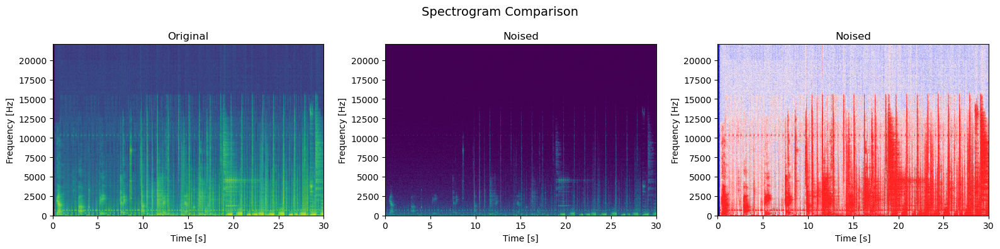

In [14]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.pcolormesh(t, f, S_orig, shading="gouraud")
plt.title("Original")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 2)
plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud", vmin=-80, vmax=0)
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 3)
plt.pcolormesh(t, f, S_orig - norm_S_orig, shading="gouraud",cmap="seismic")
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.suptitle(f"Spectrogram Comparison", fontsize=14)
plt.tight_layout()
plt.show()

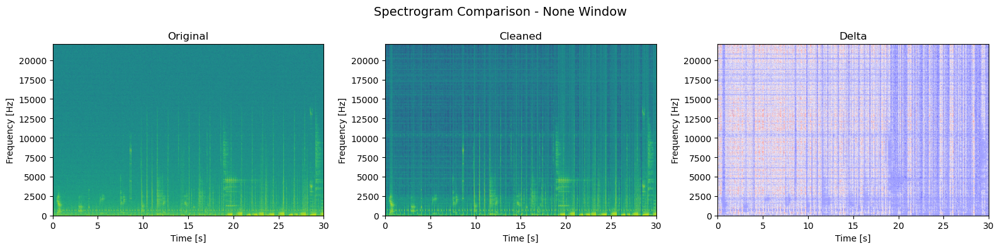

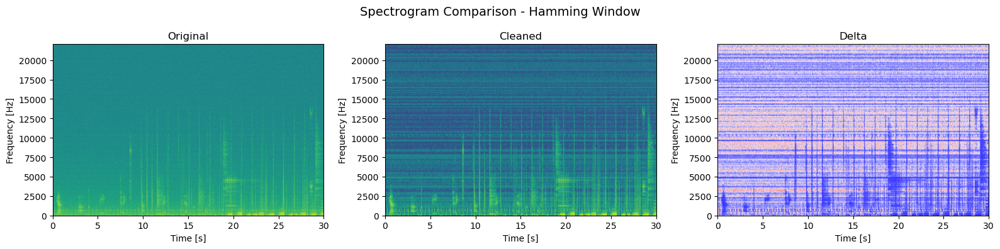

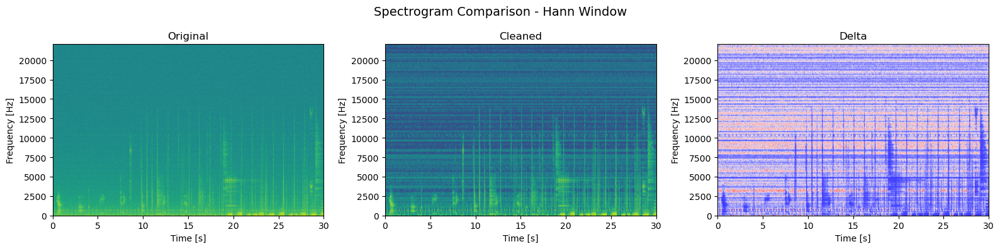

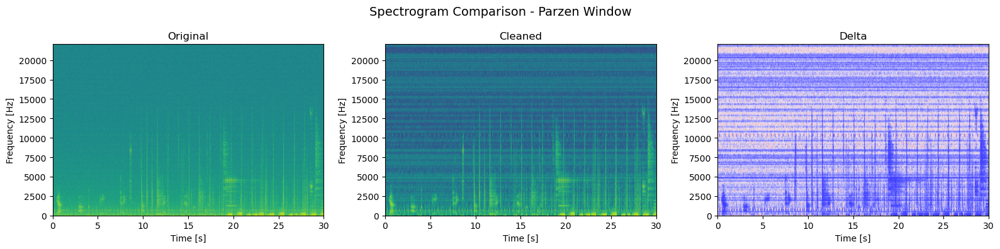

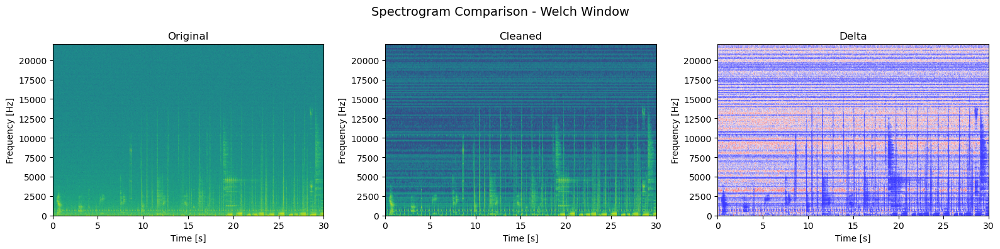

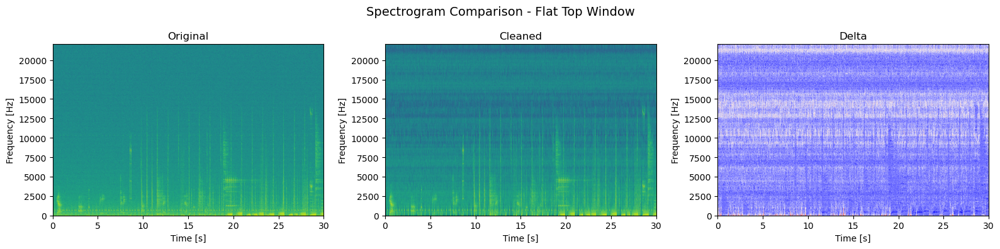

In [15]:
# samo skiciramo za faktor 2.0f (2.000000)
factor_ = '2.000000'
for key, item in window_functions.items():
    file_path = f'data/cleaned/pink/rusija{key}{factor_}.wav'
    tmp_fs, tmp_original = load_wav(file_path)

    duration = 30.0
    num_samples = int(duration * norm_fs)
    
    tmp_f, tmp_t, tmp_S_orig = spectrogram_db(tmp_original[:num_samples],tmp_fs)

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 3, 1)
    plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud")
    plt.title("Original")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 2)
    plt.pcolormesh(tmp_t, tmp_f, tmp_S_orig, shading="gouraud")
    plt.title("Cleaned")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 3)
    plt.pcolormesh(t, f, norm_S_orig - tmp_S_orig, shading="gouraud",cmap="seismic")
    plt.title("Delta")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.suptitle(f"Spectrogram Comparison - {item} Window", fontsize=14)
    plt.tight_layout()
    plt.show()


# Impulsivni šum

In [16]:
norm_fs, norm_original = load_wav("data/sample/impulsive/rusija.wav")

duration = 30.0
num_samples = int(duration * norm_fs)

norm_f, norm_t, norm_S_orig = spectrogram_db(norm_original[:num_samples],norm_fs)

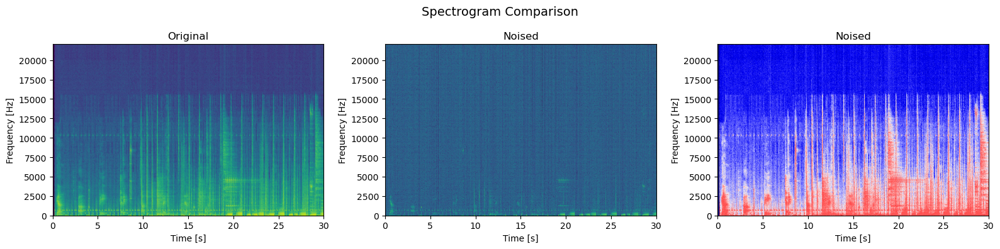

In [17]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.pcolormesh(t, f, S_orig, shading="gouraud")
plt.title("Original")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 2)
plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud", vmin=-80, vmax=0)
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.subplot(1, 3, 3)
plt.pcolormesh(t, f, S_orig - norm_S_orig, shading="gouraud",cmap="seismic")
plt.title("Noised")
plt.ylabel("Frequency [Hz]")
plt.xlabel("Time [s]")

plt.suptitle(f"Spectrogram Comparison", fontsize=14)
plt.tight_layout()
plt.show()

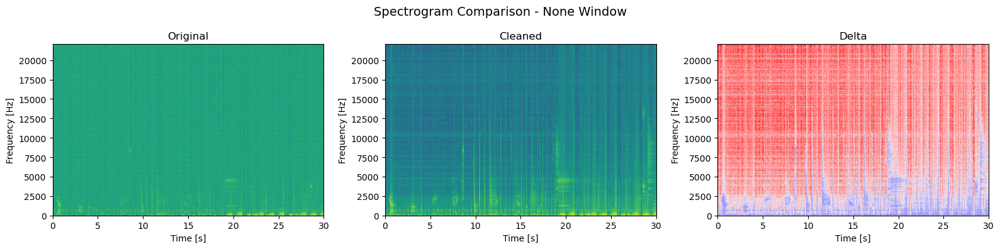

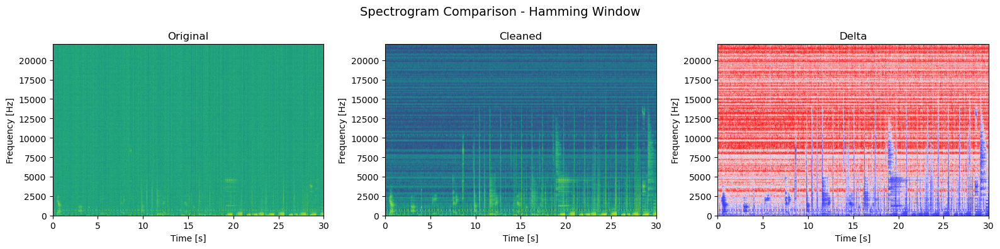

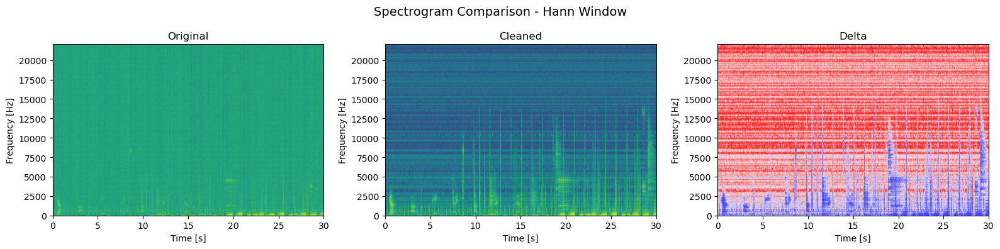

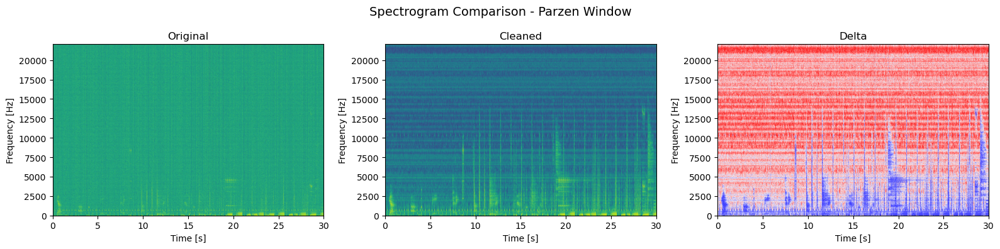

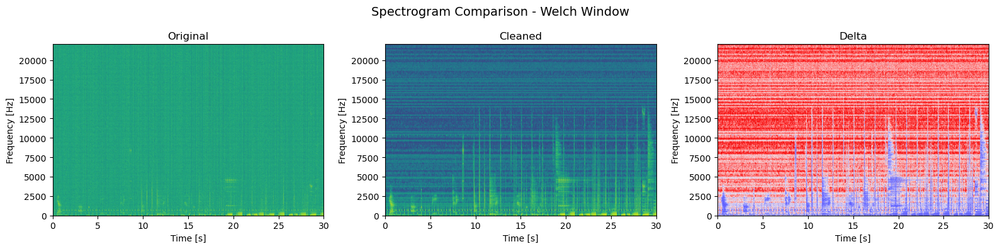

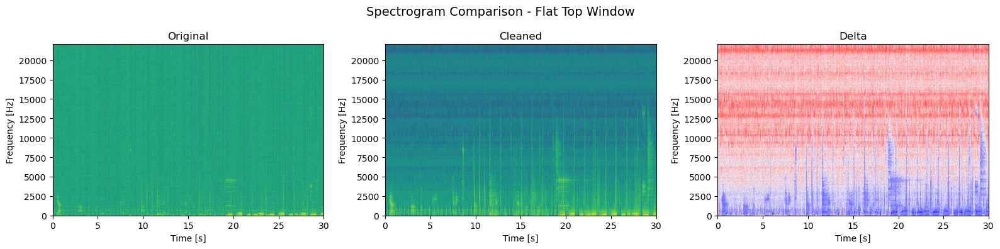

In [18]:
# samo skiciramo za faktor 2.0f (2.000000)
factor_ = '2.000000'
for key, item in window_functions.items():
    file_path = f'data/cleaned/pink/rusija{key}{factor_}.wav'
    tmp_fs, tmp_original = load_wav(file_path)

    duration = 30.0
    num_samples = int(duration * norm_fs)
    
    tmp_f, tmp_t, tmp_S_orig = spectrogram_db(tmp_original[:num_samples],tmp_fs)

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 3, 1)
    plt.pcolormesh(norm_t, norm_f, norm_S_orig, shading="gouraud")
    plt.title("Original")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 2)
    plt.pcolormesh(tmp_t, tmp_f, tmp_S_orig, shading="gouraud")
    plt.title("Cleaned")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.subplot(1, 3, 3)
    plt.pcolormesh(t, f, norm_S_orig - tmp_S_orig, shading="gouraud",cmap="seismic")
    plt.title("Delta")
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")

    plt.suptitle(f"Spectrogram Comparison - {item} Window", fontsize=14)
    plt.tight_layout()
    plt.show()
